# Problem 1: Network Compression using SVD

In [1]:
import copy
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"using device {device}")
torch.manual_seed(42)

using device cuda


In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_full = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_dataset, val_dataset = random_split(train_full, [55000,5000], generator=torch.Generator().manual_seed(42))

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

print(f"Training images {len(train_dataset)}")
print(f"validation images {len(val_dataset)}")
print(f"test images {len(test_dataset)}")


Training images 55000
validation images 5000
test images 10000


In [4]:
class MINSTClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.layers=nn.Sequential(
            nn.Linear(784, 1024),
            nn.ReLU(),

            nn.Linear(1024, 1024),
            nn.ReLU(),

            nn.Linear(1024, 1024),
            nn.ReLU(),

            nn.Linear(1024, 1024),
            nn.ReLU(),

            nn.Linear(1024, 1024),
            nn.ReLU(),

            nn.Linear(1024, 10)
        )

    def forward(self, x):
        x = self.flatten(x)
        return self.layers(x)

In [5]:
#TEST CELL 

test_model = MINSTClassifier().to(device)
dummy_input = torch.randn(32, 1, 28, 28).to(device)
output = test_model(dummy_input)
print("Output shape:", output.shape)
print("Total parameters:", sum(p.numel() for p in test_model.parameters()))

Output shape: torch.Size([32, 10])
Total parameters: 5012490


In [6]:
def evaluate_model(model, data_loader):
    model.eval()
    correct=0
    total=0
    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return 100 * correct / total

In [7]:
torch.manual_seed(42)
model = MINSTClassifier().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [8]:
num_epochs = 20
train_losses = []
val_accuracies = []

best_val_acc = 0
best_weights = None

for epoch in range(num_epochs):
    running_loss = 0
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
    avg_loss = running_loss / len(train_dataset)
    val_acc = evaluate_model(model, val_loader)
    train_losses.append(avg_loss)
    val_accuracies.append(val_acc)
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_weights = copy.deepcopy(model.state_dict())
    print(
        f"Epoch {epoch+1:2d}/{num_epochs} | "
        f"Train Loss: {avg_loss:.4f} | "
        f"Val Accuracy: {val_acc:.2f}%"
    )
model.load_state_dict(best_weights)
torch.save(model.state_dict(), "minst_baseline.pt")
print(f"\nBest validation acc: {best_val_acc:.2f}%")

Epoch  1/20 | Train Loss: 0.2778 | Val Accuracy: 96.26%
Epoch  2/20 | Train Loss: 0.1243 | Val Accuracy: 96.12%
Epoch  3/20 | Train Loss: 0.0909 | Val Accuracy: 97.42%
Epoch  4/20 | Train Loss: 0.0718 | Val Accuracy: 97.16%
Epoch  5/20 | Train Loss: 0.0629 | Val Accuracy: 97.32%
Epoch  6/20 | Train Loss: 0.0552 | Val Accuracy: 97.54%
Epoch  7/20 | Train Loss: 0.0486 | Val Accuracy: 97.44%
Epoch  8/20 | Train Loss: 0.0414 | Val Accuracy: 97.58%
Epoch  9/20 | Train Loss: 0.0331 | Val Accuracy: 97.40%
Epoch 10/20 | Train Loss: 0.0373 | Val Accuracy: 97.94%
Epoch 11/20 | Train Loss: 0.0301 | Val Accuracy: 97.42%
Epoch 12/20 | Train Loss: 0.0311 | Val Accuracy: 98.00%
Epoch 13/20 | Train Loss: 0.0284 | Val Accuracy: 97.58%
Epoch 14/20 | Train Loss: 0.0240 | Val Accuracy: 98.24%
Epoch 15/20 | Train Loss: 0.0237 | Val Accuracy: 97.96%
Epoch 16/20 | Train Loss: 0.0194 | Val Accuracy: 98.32%
Epoch 17/20 | Train Loss: 0.0200 | Val Accuracy: 98.02%
Epoch 18/20 | Train Loss: 0.0255 | Val Accuracy:

In [9]:
test_acc = evaluate_model(model, test_loader)
print(f"baseline test acc: {test_acc:.2f}%")

baseline test acc: 98.32%


In [10]:
linear_layers = [layer for layer in model.layers if isinstance(layer, nn.Linear)]
svd_factors = []

for i, layer in enumerate(linear_layers[:-1]):
    W = layer.weight.detach()
    U, S, Vh = torch.linalg.svd(W, full_matrices=False)
    svd_factors.append((U, S, Vh))
    print(f"Layer {i + 1}: W={tuple(W.shape)}, U={tuple(U.shape)}, S={tuple(S.shape)}, Vh={tuple(Vh.shape)}")

Layer 1: W=(1024, 784), U=(1024, 784), S=(784,), Vh=(784, 784)
Layer 2: W=(1024, 1024), U=(1024, 1024), S=(1024,), Vh=(1024, 1024)
Layer 3: W=(1024, 1024), U=(1024, 1024), S=(1024,), Vh=(1024, 1024)
Layer 4: W=(1024, 1024), U=(1024, 1024), S=(1024,), Vh=(1024, 1024)
Layer 5: W=(1024, 1024), U=(1024, 1024), S=(1024,), Vh=(1024, 1024)


In [11]:
def create_compressed_model(model, svd_factors, rank):
    compressed_model = copy.deepcopy(model)
    compressed_layers = [layer for layer in compressed_model.layers if isinstance(layer, nn.Linear)]
    with torch.no_grad():
        for layer, (U, S, Vh) in zip(compressed_layers[:-1], svd_factors):
            D = min(rank, len(S))
            W_approx = (U[:, :D] * S[:D]) @ Vh[:D, :]
            layer.weight.copy_(W_approx)
    return compressed_model

In [13]:
ranks = [10, 20, 50, 100, 200, 1024]
svd_accuracies = []
for rank in ranks:
    compressed_model = create_compressed_model(model, svd_factors, rank)
    accuracy = evaluate_model(compressed_model, test_loader)
    svd_accuracies.append(accuracy)
    print(f"Rank: {rank:4d} | Test acc: {accuracy:.2f}%")

Rank:   10 | Test acc: 61.04%
Rank:   20 | Test acc: 96.18%
Rank:   50 | Test acc: 98.15%
Rank:  100 | Test acc: 98.31%
Rank:  200 | Test acc: 98.29%
Rank: 1024 | Test acc: 98.32%


In [16]:
baseline_params = sum(p.numel() for p in model.parameters())
def compressed_parameter_count(model, rank):
    layers = [layer for layer in model.layers if isinstance(layer, nn.Linear)]
    total = 0
    for layer in layers[:-1]:
        D = min(rank, min(layer.weight.shape))
        total += D * (layer.in_features + layer.out_features)
        total += layer.out_features
    total += layers[-1].weight.numel()
    total += layers[-1].bias.numel()
    return total

print(f"Baseline parameters: {baseline_params}")
for rank, accuracy in zip(ranks, svd_accuracies):
    if rank == 1024:
        params = baseline_params
    else:
        params = compressed_parameter_count(model, rank)
    reduction = 100*(1-params / baseline_params)
    print(f"Rank {rank:4d} | Accuracy: {accuracy:.2f}% | Parameters: {params:,} | Reduction: {reduction:.2f}%")

Baseline parameters: 5012490
Rank   10 | Accuracy: 61.04% | Parameters: 115,370 | Reduction: 97.70%
Rank   20 | Accuracy: 96.18% | Parameters: 215,370 | Reduction: 95.70%
Rank   50 | Accuracy: 98.15% | Parameters: 515,370 | Reduction: 89.72%
Rank  100 | Accuracy: 98.31% | Parameters: 1,015,370 | Reduction: 79.74%
Rank  200 | Accuracy: 98.29% | Parameters: 2,015,370 | Reduction: 59.79%
Rank 1024 | Accuracy: 98.32% | Parameters: 5,012,490 | Reduction: 0.00%


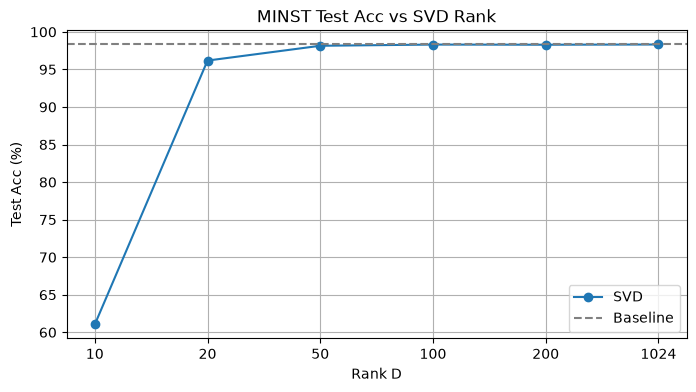

In [18]:
plt.figure(figsize=(8,4))
x_positions = range(len(ranks))
plt.plot(x_positions, svd_accuracies, marker = 'o', label = "SVD")
plt.axhline(
    test_acc,
    linestyle = "--",
    color = "gray",
    label="Baseline"
)
plt.xlabel("Rank D")
plt.ylabel("Test Acc (%)")
plt.title("MINST Test Acc vs SVD Rank")
plt.xticks(x_positions, ranks)
plt.legend()
plt.grid(True)
plt.show()